# AlphaRAD on CheXpert dataset

In [1]:
# Install dependencies
import subprocess
import sys
import time
from pathlib import Path

RUN_START = time.perf_counter()
REPO_URL = 'https://github.com/jz5426/ECCV-2026-AlphaRAD.git'
REPO_COMMIT = '59a28b0211081a99936da37902b3e5ee081056f5'
REPO = Path('/kaggle/working/alpharad_official')
INPUT = Path('/kaggle/input')
RESULTS = Path('/kaggle/working/alpharad_chexpert_official_results')
RESULTS.mkdir(parents=True, exist_ok=True)

packages = [
    'albumentations==1.3.1', 'transformers==4.57.1',
    'torchmetrics==1.8.2', 'jaxtyping==0.3.3',
    'huggingface_hub==0.36.0', 'hydra-core==1.3.2',
    'einops', 'nltk', 'timm==0.9.2',
]
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *packages], check=True)
if not (REPO / 'evaluate_zeroshot.py').is_file():
    subprocess.run(['git', 'clone', REPO_URL, str(REPO)], check=True)
subprocess.run(['git', '-C', str(REPO), 'checkout', '--detach', REPO_COMMIT], check=True)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print('AlphaRAD source:', subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip())


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.5/68.5 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.9/55.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 8.5 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.0 which is incompatible.
Cloning into '/kaggle/working/alpharad_official'...


AlphaRAD source: 59a28b0211081a99936da37902b3e5ee081056f5


HEAD is now at 59a28b0 .


In [2]:
import ast
import hashlib
import json
import re

import numpy as np
import pandas as pd
from PIL import Image

official_csv = REPO / 'configs/data_csv/chexpert.csv'
manifest = pd.read_csv(official_csv)
if len(manifest) != 668 or manifest['image'].nunique() != 668:
    raise ValueError('The pinned repository does not contain the expected 668 unique CheXpert images.')

def relative_image_path(raw_path):
    parts = Path(raw_path).parts
    patient_index = next(i for i, part in enumerate(parts) if re.fullmatch(r'patient\d+', part))
    return Path(*parts[patient_index:])

relative_paths = manifest['image'].map(relative_image_path)
first_patient = relative_paths.iloc[0].parts[0]
candidate_roots = sorted({p.parent for p in INPUT.rglob(first_patient) if p.is_dir()})
DATA_ROOT = next(
    (root for root in candidate_roots if all((root / rel).is_file() for rel in relative_paths)),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        'Attach the official CheXpert test images as an extracted Kaggle dataset. '
        'The AlphaRAD manifest needs patient64741–patient65240 (668 images); '
        'the usual CheXpert train/valid dataset does not supply this cohort. '
        'Stanford AIMI: https://stanfordmlgroup.github.io/competitions/chexpert/'
    )

manifest['image'] = [str(DATA_ROOT / rel) for rel in relative_paths]
manifest['patient_id'] = [rel.parts[0] for rel in relative_paths]
if manifest['patient_id'].nunique() != 500:
    raise ValueError('Expected 500 distinct CheXpert test patients.')
if not all((p.exists() for p in map(Path, manifest['image']))):
    raise FileNotFoundError('At least one CheXpert test image is missing.')

EVAL_CSV = RESULTS / 'chexpert_official_manifest_with_local_paths.csv'
manifest[['image', 'label', 'class']].to_csv(EVAL_CSV, index=False)
print(f'Test set: {len(manifest)} images from {manifest.patient_id.nunique()} patients')
print('Image root:', DATA_ROOT)
print('Views:', manifest['image'].str.contains('frontal').sum(), 'frontal; ',
      manifest['image'].str.contains('lateral').sum(), 'lateral')


Test set: 668 images from 500 patients
Image root: /kaggle/input/datasets/shadril238/chexpert-official-test-set/CheXpert/test
Views: 518 frontal;  150 lateral


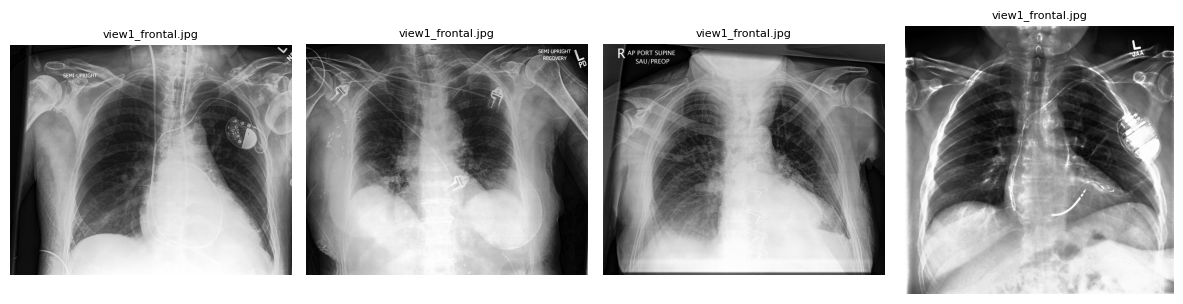

In [3]:
import matplotlib.pyplot as plt

sample_rows = manifest.iloc[[0, 1, 2, 3]]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    with Image.open(row['image']) as image:
        ax.imshow(image.convert('L'), cmap='gray')
    ax.set_title(Path(row['image']).name, fontsize=8)
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [4]:
# Load the released checkpoint and its exact image and text backbones
import torch
from huggingface_hub import HfApi, hf_hub_download, snapshot_download

if not torch.cuda.is_available():
    raise RuntimeError('Select a Kaggle GPU accelerator before evaluation.')
api = HfApi()
MODEL_REPO = 'maxxyouu/AlphaRAD'
TEXT_REPO = 'sentence-transformers/all-mpnet-base-v2'
IMAGE_REPO = 'StanfordAIMI/dinov2-base-xray-224'
TEXT_REVISION = api.model_info(TEXT_REPO).sha
IMAGE_REVISION = api.model_info(IMAGE_REPO).sha

attached_checkpoints = list(INPUT.rglob('eccv_mpnet_518.tar'))
if len(attached_checkpoints) > 1:
    raise ValueError('Attach only one copy of eccv_mpnet_518.tar.')
if attached_checkpoints:
    CHECKPOINT = attached_checkpoints[0]
    MODEL_REVISION = None
else:
    MODEL_REVISION = api.model_info(MODEL_REPO).sha
    CHECKPOINT = Path(hf_hub_download(
        repo_id=MODEL_REPO,
        filename='xraydinov2_mpnet/eccv_mpnet_518.tar',
        revision=MODEL_REVISION,
    ))

TEXT_DIR = Path(snapshot_download(
    repo_id=TEXT_REPO, revision=TEXT_REVISION,
    allow_patterns=[
        'config.json', 'model.safetensors', 'vocab.txt', 'tokenizer.json',
        'tokenizer_config.json', 'special_tokens_map.json',
    ],
))
IMAGE_DIR = Path(snapshot_download(
    repo_id=IMAGE_REPO, revision=IMAGE_REVISION,
    allow_patterns=['config.json', 'model.safetensors', 'preprocessor_config.json'],
))
print('GPU:', torch.cuda.get_device_name(0))
print('Checkpoint:', CHECKPOINT.name)


xraydinov2_mpnet/eccv_mpnet_518.tar:   0%|          | 0.00/791M [00:00<?, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

...

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

GPU: Tesla T4
Checkpoint: eccv_mpnet_518.tar


In [5]:
# Replace only the repository's placeholder cache paths with local backbone paths
source_path = REPO / 'cxrclip/evaluator.py'
source = subprocess.check_output(
    ['git', '-C', str(REPO), 'show', f'{REPO_COMMIT}:cxrclip/evaluator.py'],
    text=True,
)
old_text = "'cache_path/to/ sentence-transformers/all-mpnet-base-v2 or Laihaoran/BioClinicalMPBERT'"
old_image = "'cache_path/to/xraydinov2'"
if source.count(old_text) != 1 or source.count(old_image) != 1:
    raise ValueError('The expected official cache placeholders have changed.')
source = source.replace(old_text, repr(str(TEXT_DIR)))
source = source.replace(old_image, repr(str(IMAGE_DIR)))
image_line = f"ckpt['config']['model']['image_encoder']['cache_dir'] = {str(IMAGE_DIR)!r}"
source = source.replace(
    image_line,
    image_line + "\n        ckpt['config']['tokenizer']['cache_dir'] = " + repr(str(TEXT_DIR)),
)
compile(source, str(source_path), 'exec')
source_path.write_text(source)
print('Configured official evaluator backbone and tokenizer paths.')


Configured official evaluator backbone and tokenizer paths.


In [6]:
# Keep the official CheXpert dataset key, label list, transforms, and checkpoint settings
from omegaconf import OmegaConf
from cxrclip import seed_everything
from cxrclip.evaluator_utils import get_class_list

SEED = 1234
TASK_EPOCHS = 0
INFERENCE_BATCH_SIZE = 2
seed_everything(SEED)

dataset_config = OmegaConf.to_container(
    OmegaConf.load(REPO / 'configs/data_test/chexpert.yaml'), resolve=False,
)
dataset_config['chexpert']['data_path'] = str(EVAL_CSV)
loader_config = OmegaConf.to_container(
    OmegaConf.load(REPO / 'configs/dataloader/dataloader_256.yaml'), resolve=False,
)
loader_config['test'].update(batch_size=INFERENCE_BATCH_SIZE, num_workers=2, prefetch_factor=2)
eval_config = {
    'test': {'checkpoint': [str(CHECKPOINT)], 'seed': SEED},
    'data_test': dataset_config,
    'dataloader': loader_config,
}
LABELS = get_class_list('chexpert')
manifest_labels = sorted({label for value in manifest['class'] for label in ast.literal_eval(value)})
print(f'Official evaluator queries: {len(LABELS)} findings')
print(f'Manifest observations: {len(manifest_labels)}')
print('Queries:', ', '.join(LABELS))
print('Manifest observations not queried:', ', '.join(sorted(set(manifest_labels) - set(LABELS))))
print('No CheXpert training epochs; inference batch size:', INFERENCE_BATCH_SIZE)


Official evaluator queries: 12 findings
Manifest observations: 14
Queries: No Finding, Enlarged Cardiomediastinum, Cardiomegaly, Lung Opacity, Lung Lesion, Edema, Consolidation, Pneumonia, Atelectasis, Pneumothorax, Pleural Effusion, Fracture
Manifest observations not queried: Pleural Other, Support Devices
No CheXpert training epochs; inference batch size: 2


In [7]:
# Run the official Evaluator.evaluate_clip_offline scoring and metric path
from cxrclip.evaluator import Evaluator

evaluator = Evaluator(eval_config, [str(CHECKPOINT)], 'test')
if evaluator.zero_shot_method != 'zeroshot_binary_dqn':
    raise ValueError('The released checkpoint does not select AlphaRAD zero-shot DQN scoring.')

captured = {}
official_gather = evaluator.gather_zeroshot_dqn_classification_statistics
def capture_predictions(class_list, predictions, label_names):
    captured['class_list'] = list(class_list)
    captured['predictions'] = np.asarray(predictions)
    captured['label_names'] = label_names
    return official_gather(class_list, predictions, label_names)

evaluator.gather_zeroshot_dqn_classification_statistics = capture_predictions
EVAL_START = time.perf_counter()
official_results = evaluator.evaluate_clip_offline(str(CHECKPOINT), 'chexpert')
EVAL_SECONDS = time.perf_counter() - EVAL_START
score_block = official_results['zeroshot_binary']
print(f'Official CheXpert macro AUROC: {score_block["AUROC(Avg)"]:.3f}')
print(f'Official CheXpert macro AUPRC: {score_block["PR_AUROC(Avg)"]:.3f}')
print(f'Evaluation time: {EVAL_SECONDS / 60:.1f} minutes')


Device: cuda
missing: []
unexpected: ['logit_scale_aux']


[chexpert]: 100%|██████████| 334/334 [01:25<00:00,  3.90it/s]


Official CheXpert macro AUROC: 0.893
Official CheXpert macro AUPRC: 0.609
Evaluation time: 1.4 minutes


In [8]:
# Display the per-finding metrics returned by the official repository
metrics_df = pd.DataFrame({name: score_block[name] for name in LABELS}).T
metrics_df.index.name = 'finding'
print(metrics_df.round(3).to_string())
print('Repository reference: 0.893 CheXpert AUROC; interpret with its 12-query/14-observation mismatch.')
print(f'Observed difference from repository reference: {score_block["AUROC(Avg)"] - 0.893:+.3f}')


                            AUROC  PR_AUROC  Accuracy     F1  Precision  Recall
finding                                                                        
No Finding                  0.877     0.725     0.901  0.694      0.701   0.688
Enlarged Cardiomediastinum  0.877     0.841     0.554  0.000      0.000   0.000
Cardiomegaly                0.910     0.791     0.783  0.306      0.941   0.183
Lung Opacity                0.796     0.740     0.539  0.013      1.000   0.006
Lung Lesion                 0.916     0.432     0.979  0.000      0.000   0.000
Edema                       0.931     0.636     0.883  0.188      0.818   0.106
Consolidation               0.870     0.378     0.951  0.154      0.750   0.086
Pneumonia                   0.840     0.472     0.982  0.455      0.625   0.357
Atelectasis                 0.885     0.730     0.816  0.667      0.644   0.691
Pneumothorax                0.955     0.543     0.984  0.593      0.471   0.800
Pleural Effusion            0.948     0.

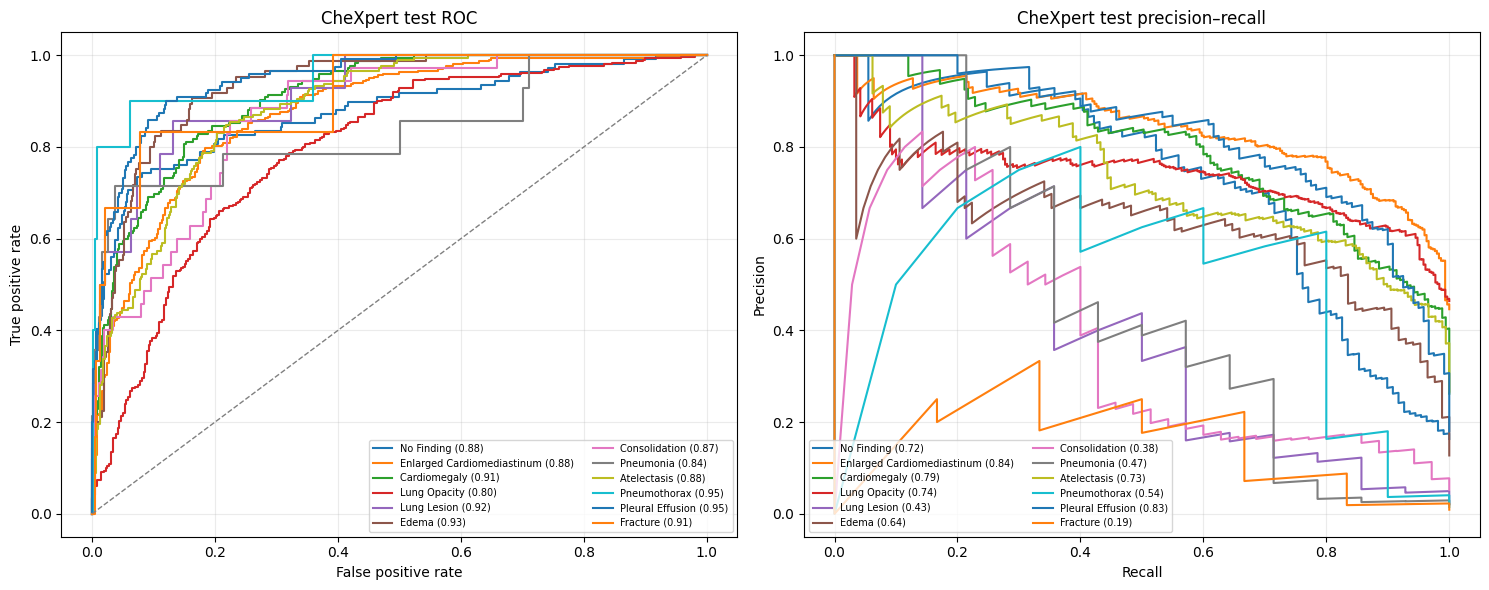

In [9]:
# Plot ROC and precision-recall curves from the official evaluator predictions
from sklearn.metrics import precision_recall_curve, roc_curve
from cxrclip.evaluator_utils import disease_list_mapping, disease_name_mapping

raw_scores = captured['predictions']
scores = np.asarray(raw_scores).reshape(len(manifest), len(LABELS), -1)
if scores.shape[2] != 1:
    raise ValueError(f'Expected one positive score per finding, got {scores.shape}.')
scores = scores[:, :, 0]
if captured['class_list'] != LABELS or len(captured['label_names']) != len(manifest):
    raise ValueError('Prediction order does not match the official CheXpert label order.')
if evaluator.data_loader_dict['chexpert'].dataset.df['image'].tolist() != manifest['image'].tolist():
    raise ValueError('The evaluator changed the manifest row order.')

truth = np.asarray([
    [int(disease_name_mapping(label) in disease_list_mapping(row)) for label in LABELS]
    for row in captured['label_names']
], dtype=int)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for column, label in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(truth[:, column], scores[:, column])
    precision, recall, _ = precision_recall_curve(truth[:, column], scores[:, column])
    axes[0].plot(fpr, tpr, label=f'{label} ({metrics_df.loc[label, "AUROC"]:.2f})')
    axes[1].plot(recall, precision, label=f'{label} ({metrics_df.loc[label, "PR_AUROC"]:.2f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(title='CheXpert test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='CheXpert test precision–recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(RESULTS / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


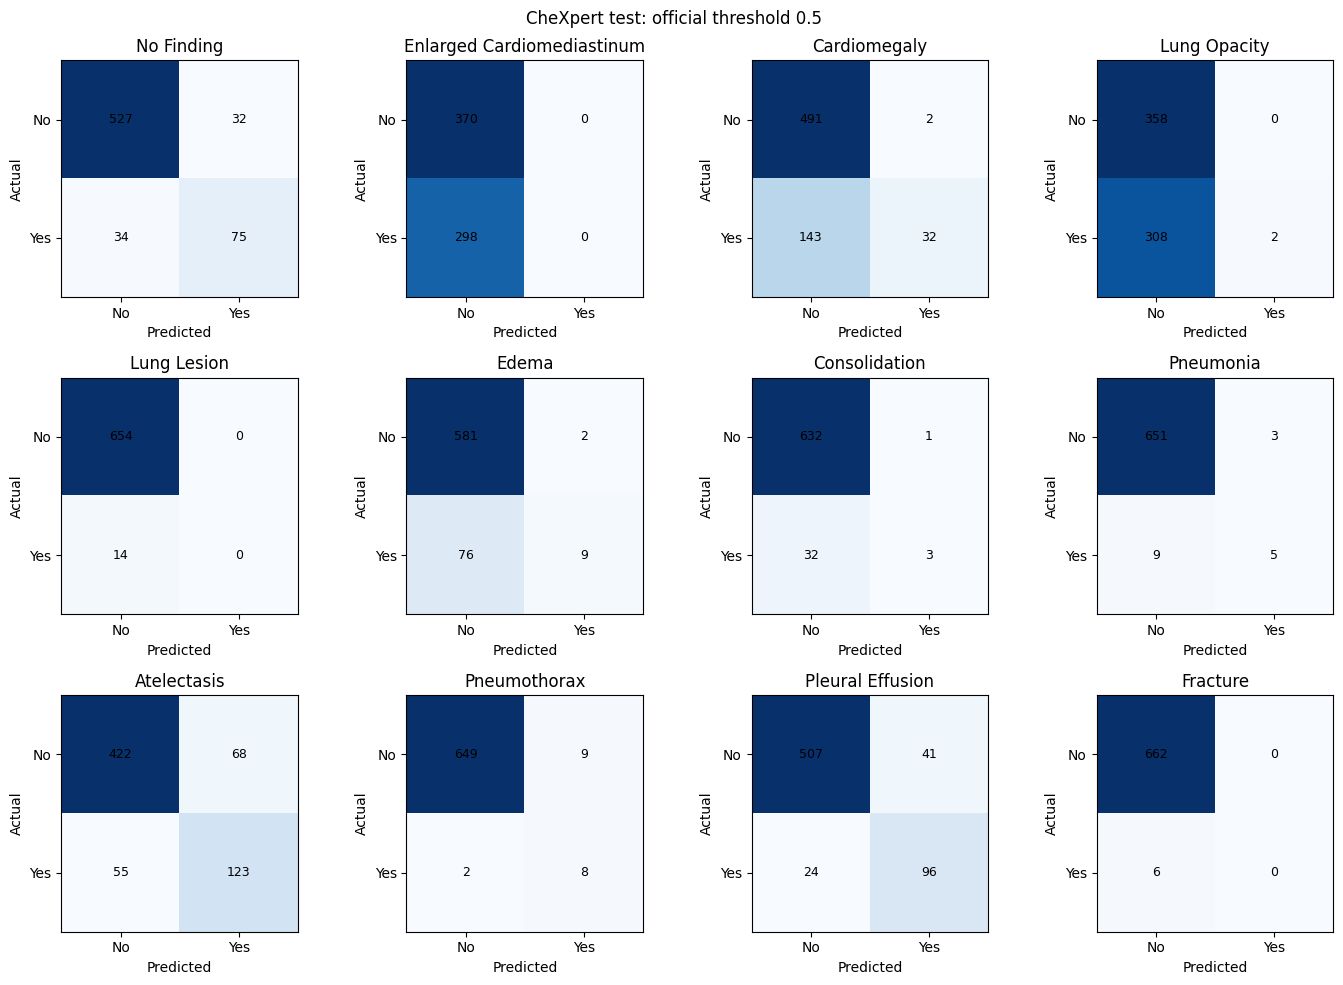

In [10]:
# Plot the official fixed-threshold confusion matrices for all queried findings
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for column, label in enumerate(LABELS):
    ax = axes.flat[column]
    matrix = confusion_matrix(truth[:, column], scores[:, column] > 0.5, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center', fontsize=9)
    ax.set(title=label, xticks=[0, 1], yticks=[0, 1],
           xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'],
           xlabel='Predicted', ylabel='Actual')
fig.suptitle('CheXpert test: official threshold 0.5')
fig.tight_layout()
fig.savefig(RESULTS / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


In [11]:
# Save the scores, official metrics, source information, and run time
predictions_df = manifest[['image', 'patient_id']].copy()
for column, label in enumerate(LABELS):
    predictions_df[f'{label}_label'] = truth[:, column]
    predictions_df[f'{label}_score'] = scores[:, column]
    predictions_df[f'{label}_prediction'] = (scores[:, column] > 0.5).astype(int)
predictions_df.to_csv(RESULTS / 'predictions.csv', index=False)
metrics_df.to_csv(RESULTS / 'official_metrics.csv')

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

run_info = {
    'protocol': 'released AlphaRAD zero-shot chexpert evaluator',
    'source_repo': REPO_URL,
    'source_commit': REPO_COMMIT,
    'manifest_rows': len(manifest),
    'patients': int(manifest.patient_id.nunique()),
    'queries': LABELS,
    'manifest_observations': manifest_labels,
    'task_training_epochs': TASK_EPOCHS,
    'inference_batch_size': INFERENCE_BATCH_SIZE,
    'checkpoint_sha256': sha256(CHECKPOINT),
    'official_manifest_sha256': sha256(official_csv),
    'model_hub_revision': MODEL_REVISION,
    'text_hub_revision': TEXT_REVISION,
    'image_hub_revision': IMAGE_REVISION,
    'macro_AUROC': float(score_block['AUROC(Avg)']),
    'evaluation_seconds': EVAL_SECONDS,
    'total_notebook_seconds': time.perf_counter() - RUN_START,
    'source_edits': 'Local text, image, and tokenizer cache paths only.',
}
(RESULTS / 'run_info.json').write_text(json.dumps(run_info, indent=2))
print('Saved results to:', RESULTS)
print(f'Total notebook time: {run_info["total_notebook_seconds"] / 60:.1f} minutes')


Saved results to: /kaggle/working/alpharad_chexpert_official_results
Total notebook time: 3.9 minutes
